# M1: Linear Quantile Regression on CLIP Album-Cover Features

**Research question.** Does a song's album cover explain its popularity *beyond* its audio features and its artist's popularity (APS)? And does the answer differ for weakly, moderately and highly popular songs?

**Approach.** Each cover is turned into a 512-number vector by a pretrained, frozen CLIP image encoder. Those vectors are compressed with PCA to $k$ components, and the components are added to the quantile regression from the M0 notebook (`Quantile_Regression_APS_Predictor.ipynb`). M0 and M1 are then compared **on the same songs and the same cross-validation folds**.

The model is still linear in its predictors. The nonlinearity sits in the CLIP encoder, which maps pixels to features. This notebook answers the first question from the slides: *does the cover add information?* The nonlinear models (M2) are a separate step.

---
## Model specification

**Dependent variable.** $Y_i$ = `song_popularity` (0-100).

**Predictors.** $\tilde{\mathbf{x}}_i$: the ten z-scored audio features from M0. $\widetilde{APS}_i$: z-scored artist score. $\tilde{\mathbf{u}}_i \in \mathbb{R}^k$: z-scored principal-component scores of the song's CLIP cover embedding.

**Cover features.** With $f$ the frozen CLIP image encoder and $I_i$ the cover image,

$$
z_i = \frac{f(I_i)}{\lVert f(I_i)\rVert} \in \mathbb{R}^{512}, \qquad
u_i = W_k^\top (z_i - \bar z) \in \mathbb{R}^{k},
$$

where $W_k$ holds the first $k$ principal directions of the cover embeddings. Each $u_{ij}$ is then z-scored, so every coefficient is in *popularity points per 1 SD of that cover direction*.

**The model.** For $\tau \in \{0.10, 0.25, 0.50, 0.75, 0.90\}$:

$$
Q_\tau\!\left(Y_i \mid \tilde{\mathbf{x}}_i, \widetilde{APS}_i, \tilde{\mathbf{u}}_i\right)
= \beta_0(\tau) + \tilde{\mathbf{x}}_i^\top \boldsymbol\beta(\tau) + \gamma(\tau)\,\widetilde{APS}_i + \tilde{\mathbf{u}}_i^\top \boldsymbol\theta(\tau)
$$

M0 is the special case $\boldsymbol\theta(\tau) = \mathbf{0}$.

**Estimation.**

$$
\big(\hat\beta_0, \hat{\boldsymbol\beta}, \hat\gamma, \hat{\boldsymbol\theta}\big)(\tau)
= \arg\min \sum_{i=1}^{n} \rho_\tau\!\Big(Y_i - \beta_0 - \tilde{\mathbf{x}}_i^\top\boldsymbol\beta - \gamma\,\widetilde{APS}_i - \tilde{\mathbf{u}}_i^\top\boldsymbol\theta\Big),
\qquad \rho_\tau(u) = u\,\big(\tau - \mathbf{1}\{u<0\}\big)
$$

**Hypotheses.**

1. *Does the cover add information?* Jointly, $H_0:\ \boldsymbol\theta(\tau) = \mathbf{0}$ at each $\tau$, using a cluster-bootstrap covariance and a Hotelling $F$ test (section 7 explains why not the usual $\chi^2_k$ Wald test).
2. *Does it improve prediction?* $\Delta(\tau) = R^1_{\text{M1}}(\tau) - R^1_{\text{M0}}(\tau) > 0$ out of sample, with a cluster-bootstrap interval.
3. *Does the cover absorb the artist effect?* Compare $\hat\gamma(\tau)$ in M0 and M1.

---
## Assumptions, and where each is checked

| # | Assumption | Where it is handled |
|---|---|---|
| 1 | **Correct specification:** at each $\tau$ the conditional quantile is linear in $(\tilde{\mathbf{x}}, \widetilde{APS}, \tilde{\mathbf{u}})$ | Linear in pixels is *not* assumed, only in CLIP directions. The $k$-sensitivity curve (section 6) and M2 later test this. |
| 2 | **Independence across clusters**, any dependence within a cluster | Clusters join artists who share an album cover (section 3); clustered sandwich SEs for single coefficients, cluster bootstrap for the joint test (section 7) |
| 3 | **Positive, continuous density** of $Y$ at the $\tau$-quantile | Approximate: popularity is an integer with a spike at 0 (same caveat as M0) |
| 4 | **Full-rank design** | PCs are uncorrelated by construction; VIFs reported (section 7) |
| 5 | **Frozen encoder trained on independent data:** CLIP never saw popularity, so $z_i$ is a fixed transformation of the image | Holds by construction (pretrained weights, no fine-tuning) |
| 6 | **No leakage:** PCA and the choice of $k$ use training data only | PCA is refitted inside every training fold (section 5). $k$ is fixed before looking at results (`K_MAIN`); the $k$-curve is a sensitivity check, not a selection step. |
| 7 | **Cover-song match is correct;** one cover per album | From the MusicBrainz matching step; inspect the sample grid in the download notebook |

*Not assumed:* constant variance, normal or symmetric errors (as in M0).

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm, chi2, f as fdist
from statsmodels.regression.quantile_regression import hall_sheather
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

# ---------------- configuration ----------------
TAUS        = [0.10, 0.25, 0.50, 0.75, 0.90]
WINSORIZE   = True       # same as M0
K_MAIN      = 20         # number of CLIP principal components in the main model; fixed BEFORE looking at results
K_GRID      = [0, 2, 5, 10, 20, 30, 50]   # sensitivity check (0 = M0)
N_SPLITS    = 5          # artist-grouped CV folds, as in M0
N_BOOT      = 2000       # cluster-bootstrap draws for the M1 - M0 difference (cheap: no refitting)
N_BOOT_COV  = 199        # cluster-bootstrap refits for the joint test of the cover coefficients (slow: ~1 refit per draw per tau)
SEED        = 0

CLIP_MODEL  = "openai/clip-vit-base-patch32"   # 512-dim embeddings; "openai/clip-vit-large-patch14" (768-dim) is stronger but slower
BATCH_SIZE  = 64

COVER_DIR   = Path("cover_art")
IMG_DIR     = COVER_DIR / "images"
MANIFEST    = COVER_DIR / "song_cover_manifest.csv"
EMB_CACHE   = COVER_DIR / f"clip_embeddings_{CLIP_MODEL.split('/')[-1]}.npz"
OUT_DIR     = Path("m1_outputs"); OUT_DIR.mkdir(exist_ok=True)

Y     = "song_popularity"
AUDIO = ["song_duration_ms", "acousticness", "danceability", "energy", "instrumentalness",
         "liveness", "loudness", "speechiness", "tempo", "audio_valence"]
XVARS = AUDIO + ["APS"]
ZVARS = ["z_" + c for c in XVARS]
LABEL = {"const": "Intercept", "z_song_duration_ms": "duration", "z_acousticness": "acousticness",
         "z_danceability": "danceability", "z_energy": "energy", "z_instrumentalness": "instrumentalness",
         "z_liveness": "liveness", "z_loudness": "loudness", "z_speechiness": "speechiness",
         "z_tempo": "tempo", "z_audio_valence": "valence", "z_APS": "APS (artist score)"}
rng = np.random.default_rng(SEED)

## 2. Estimation sample (same construction as M0), then attach covers

The first part repeats M0's cell exactly: drop duplicate rows, join the APS on artist name and lifetime streams, drop `tempo = 0`, winsorize duration and loudness, keep songs whose artist has an APS. Then each song is matched to its cover through `song_cover_manifest.csv` on song title and primary artist.

In [2]:
def find_file(filename):
    path = Path(filename)
    if path.exists():
        return path
    for parent in Path.cwd().parents:
        if (parent / filename).exists():
            return parent / filename
    raise FileNotFoundError(f"File {filename} not found in current or parent directories.")

songs_raw = pd.read_csv(find_file("song_data_with_artists.csv"))
ranks     = pd.read_csv(find_file("artist_popularity_rankings.csv"))

steps = [("Rows in song file", len(songs_raw))]
songs = songs_raw.drop_duplicates().reset_index(drop=True)
steps.append(("After dropping exact duplicate rows", len(songs)))

song_keys = songs.copy(); song_keys["_streams_key"] = pd.to_numeric(song_keys["artist_streams"], errors="coerce").round(6)
rank_keys = ranks.copy(); rank_keys["_streams_key"] = pd.to_numeric(rank_keys["Streams"], errors="coerce").round(6)
df = song_keys.merge(rank_keys[["Artist", "_streams_key", "APS"]],
                     left_on=["artist_stats_for", "_streams_key"], right_on=["Artist", "_streams_key"],
                     how="left", validate="m:1").drop(columns=["Artist", "_streams_key"])

df = df[df["tempo"] > 0].copy()
steps.append(("After dropping tempo = 0", len(df)))
if WINSORIZE:
    for c in ["song_duration_ms", "loudness"]:
        lo, hi = df[c].quantile([0.005, 0.995])
        df[c] = df[c].clip(lo, hi)

aps_sample = df[df["APS"].notna()].copy()                 # this is M0's estimation sample
steps.append(("After keeping songs whose artist has an APS (M0 sample)", len(aps_sample)))

# ---------------- attach covers ----------------
manifest = pd.read_csv(find_file(str(MANIFEST)))
manifest = manifest[manifest["has_cover"].astype(bool)].drop_duplicates(["song_name", "artist_primary"])
manifest["img_path"] = [str(IMG_DIR / f"{rg}.jpg") for rg in manifest["rg_id"]]   # rebuild path: works on any OS
manifest = manifest[[Path(p).exists() for p in manifest["img_path"]]]

aps_sample = aps_sample.merge(manifest[["song_name", "artist_primary", "rg_id", "img_path", "album", "date"]],
                              on=["song_name", "artist_primary"], how="left", validate="m:1")
aps_sample["has_cover"] = aps_sample["rg_id"].notna()
m = aps_sample[aps_sample["has_cover"]].copy().reset_index(drop=True)
steps.append(("After keeping songs with a downloaded cover (M1 sample)", len(m)))

attr = pd.DataFrame(steps, columns=["Step", "Songs remaining"])
attr["Removed"] = (-attr["Songs remaining"].diff()).fillna(0).astype(int)
display(attr)
print(f"Songs: {len(m):,} | artists: {m['artist_stats_for'].nunique():,} | distinct covers: {m['rg_id'].nunique():,}")

,Step,Songs remaining,Removed
0,Rows in song file,18835,0
1,After dropping exact duplicate rows,14926,3909
2,After dropping tempo = 0,14924,2
3,After keeping songs whose artist has an APS (M...,6181,8743
4,After keeping songs with a downloaded cover (M...,6008,173


Songs: 6,008 | artists: 1,663 | distinct covers: 4,330


### Selection check: are songs with covers different?

M1 can only use songs that were matched to a cover. If those songs are more (or less) popular than the rest of the M0 sample, results apply to that subset only. M0 is therefore **refitted on the M1 sample** for every comparison below, so the two models always see the same songs.

Share of the M0 sample with a cover: 97.2%


has_cover,no cover,with cover,difference
song_popularity,50.017,55.105,5.087
APS,60.241,65.642,5.401
song_duration_ms,215193.896,220794.340,5600.444
acousticness,0.253,0.228,-0.025
danceability,0.663,0.632,-0.031
energy,0.652,0.663,0.010
instrumentalness,0.033,0.034,0.000
liveness,0.167,0.182,0.015
loudness,-7.084,-6.977,0.107
speechiness,0.107,0.102,-0.005


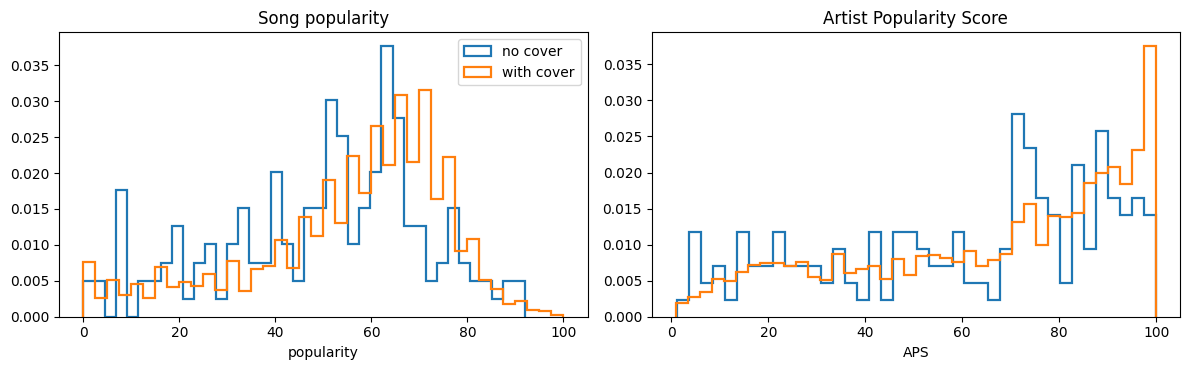

In [3]:
sel = (aps_sample.groupby("has_cover")[[Y, "APS"] + AUDIO].mean().T
       .rename(columns={False: "no cover", True: "with cover"}))
sel["difference"] = sel["with cover"] - sel["no cover"]
print(f"Share of the M0 sample with a cover: {aps_sample['has_cover'].mean():.1%}")
display(sel.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for flag, lab in [(False, "no cover"), (True, "with cover")]:
    ax[0].hist(aps_sample.loc[aps_sample["has_cover"] == flag, Y], bins=40, histtype="step", density=True, lw=1.6, label=lab)
    ax[1].hist(aps_sample.loc[aps_sample["has_cover"] == flag, "APS"], bins=40, histtype="step", density=True, lw=1.6, label=lab)
ax[0].set(title="Song popularity", xlabel="popularity"); ax[1].set(title="Artist Popularity Score", xlabel="APS")
ax[0].legend(); plt.tight_layout(); plt.savefig(OUT_DIR / "selection_check.png", dpi=200); plt.show()

## 3. Clusters for standard errors and cross-validation

M0 treats each artist as a cluster. With covers there is one more link: two artists can share an album (e.g. a featured artist's song is on the lead artist's album). If they ended up in different folds, the test fold would contain a cover the model was trained on. Clusters are therefore the **connected groups** of artists linked by a shared cover. In practice this merges only a few artists.

In [4]:
def connected_groups(artists, albums):
    # Union-find: artists sharing any album end up in one group.
    parent = {}
    def find(a):
        parent.setdefault(a, a)
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for art, alb in zip(artists, albums):
        ra, rb = find("A|" + str(art)), find("R|" + str(alb))
        if ra != rb: parent[ra] = rb
    return pd.factorize(np.array([find("A|" + str(a)) for a in artists]))[0]

groups = connected_groups(m["artist_stats_for"], m["rg_id"])
G = groups.max() + 1
print(f"artists: {m['artist_stats_for'].nunique():,}  ->  clusters after linking shared covers: {G:,}")

artists: 1,663  ->  clusters after linking shared covers: 1,604


## 4. CLIP embeddings of the covers

Each distinct cover is encoded once with the frozen CLIP image encoder, normalised to unit length, and cached to disk. Re-running the notebook reuses the cache.

**Install once:** `pip install torch transformers`. The first run downloads the CLIP weights (about 600 MB for ViT-B/32). On a laptop CPU, a few thousand covers take roughly 5-15 minutes; a GPU is used automatically if present.

In [5]:
# CLIP-LOAD: loads the encoder and defines encode_images / encode_texts
import torch
from transformers import CLIPModel, CLIPProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
clip_model = CLIPModel.from_pretrained(CLIP_MODEL).to(DEVICE).eval()
clip_proc  = CLIPProcessor.from_pretrained(CLIP_MODEL)

def _as_tensor(out):
    # Newer transformers versions may wrap the features in an output object.
    if isinstance(out, torch.Tensor): return out
    for attr in ("image_embeds", "text_embeds", "pooler_output"):
        if getattr(out, attr, None) is not None: return getattr(out, attr)
    return out[0]

@torch.no_grad()
def encode_images(paths, batch_size=BATCH_SIZE):
    feats = []
    for i in range(0, len(paths), batch_size):
        imgs = []
        for p in paths[i:i + batch_size]:
            with Image.open(p) as im:
                imgs.append(im.convert("RGB"))
        inputs = clip_proc(images=imgs, return_tensors="pt").to(DEVICE)
        feats.append(_as_tensor(clip_model.get_image_features(**inputs)).float().cpu().numpy())
        if (i // batch_size) % 10 == 0:
            print(f"  encoded {min(i + batch_size, len(paths)):,}/{len(paths):,}")
    return np.vstack(feats)

@torch.no_grad()
def encode_texts(prompts):
    inputs = clip_proc(text=list(prompts), return_tensors="pt", padding=True).to(DEVICE)
    return _as_tensor(clip_model.get_text_features(**inputs)).float().cpu().numpy()

print("CLIP model:", CLIP_MODEL, "| device:", DEVICE)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

C:\torchsite\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kiwib\.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\torchsite\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store dupl

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model: openai/clip-vit-base-patch32 | device: cpu


In [6]:
covers = m[["rg_id", "img_path"]].drop_duplicates("rg_id").reset_index(drop=True)

cache = {}
if EMB_CACHE.exists():
    d = np.load(EMB_CACHE, allow_pickle=False)
    cache = dict(zip(d["rg_id"].tolist(), d["emb"]))
todo = covers[~covers["rg_id"].isin(cache)]
print(f"covers: {len(covers):,} | cached: {len(covers) - len(todo):,} | to encode now: {len(todo):,}")
if len(todo):
    new = encode_images(todo["img_path"].tolist())
    cache.update(zip(todo["rg_id"], new))
    np.savez(EMB_CACHE, rg_id=np.array(list(cache)), emb=np.vstack(list(cache.values())))

E_cover = np.vstack([cache[r] for r in covers["rg_id"]])
E_cover = E_cover / np.linalg.norm(E_cover, axis=1, keepdims=True)          # z_i: unit length
cover_row = pd.Series(np.arange(len(covers)), index=covers["rg_id"])
song_cover_idx = cover_row.loc[m["rg_id"]].to_numpy()                       # song i -> its cover's row
E = E_cover[song_cover_idx]                                                  # one embedding per song
print("embedding matrix (songs x dims):", E.shape)

covers: 4,330 | cached: 0 | to encode now: 4,330
  encoded 64/4,330
  encoded 704/4,330
  encoded 1,344/4,330
  encoded 1,984/4,330
  encoded 2,624/4,330
  encoded 3,264/4,330
  encoded 3,904/4,330
embedding matrix (songs x dims): (6008, 512)


### Sanity check: do the embeddings group similar covers?

For a few random covers, show the covers CLIP considers most similar (cosine similarity). If the neighbours share style, colour or subject, the embeddings carry visual information.

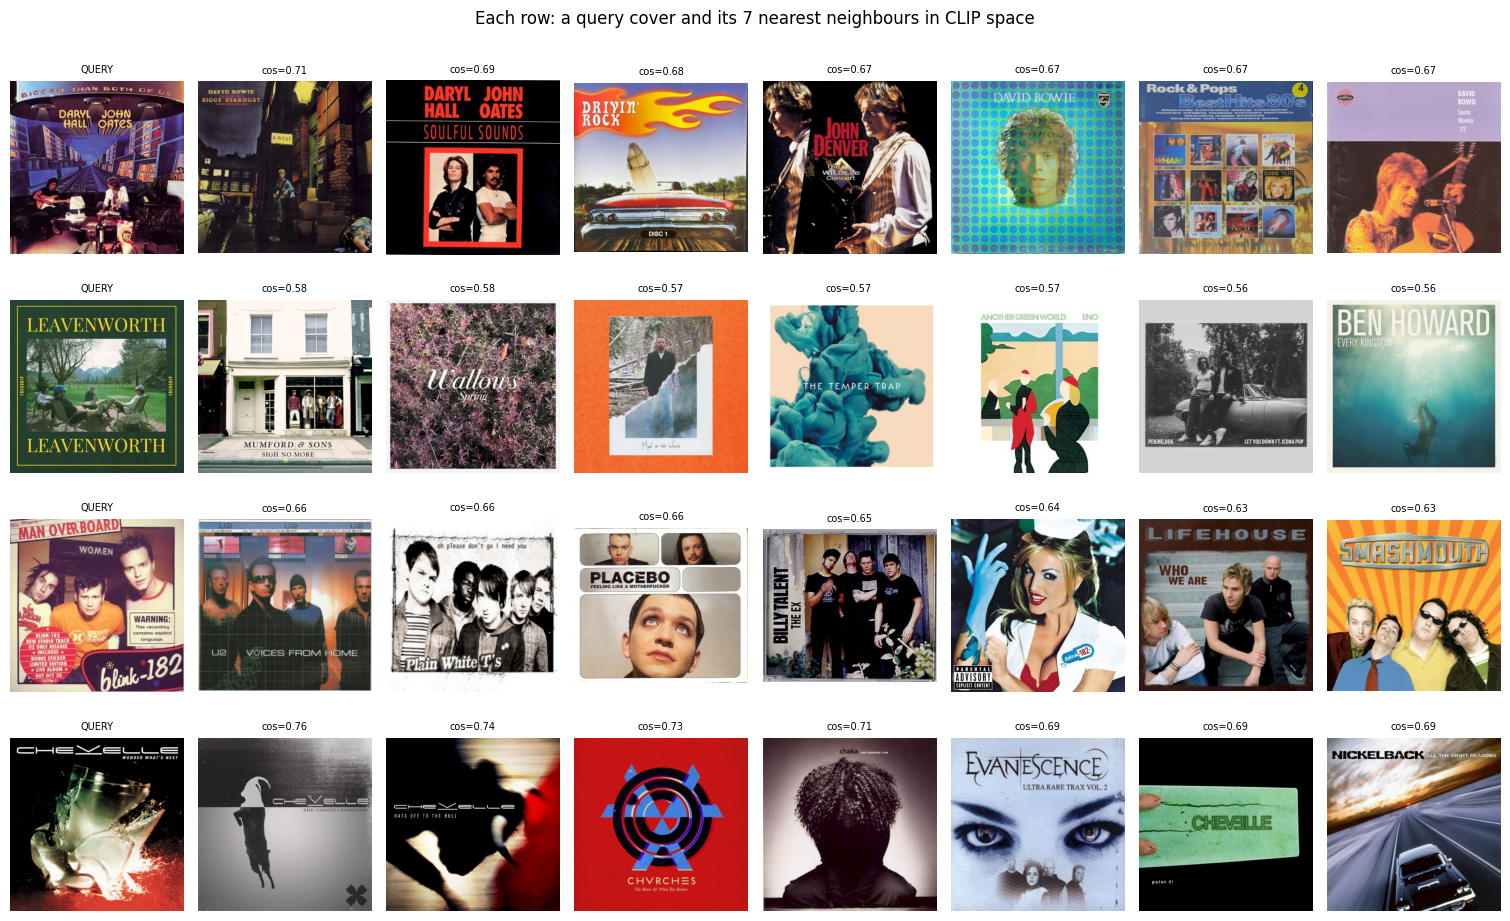

In [7]:
def show_covers(rows, titles, ncols=8, size=1.9, suptitle=None, fname=None):
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * (size + 0.45)))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, r, t in zip(axes, rows, titles):
        with Image.open(covers.loc[r, "img_path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(t, fontsize=7)
    if suptitle: fig.suptitle(suptitle, y=1.0)
    plt.tight_layout()
    if fname: plt.savefig(OUT_DIR / fname, dpi=150)
    plt.show()

album_name = m.drop_duplicates("rg_id").set_index("rg_id")["album"]
queries = rng.choice(len(covers), size=min(4, len(covers)), replace=False)
rows, titles = [], []
for q in queries:
    sims = E_cover @ E_cover[q]
    nn = np.argsort(-sims)[:8]
    rows += list(nn)
    titles += ["QUERY" if j == q else f"cos={sims[j]:.2f}" for j in nn]
show_covers(rows, titles, suptitle="Each row: a query cover and its 7 nearest neighbours in CLIP space",
            fname="nearest_neighbours.png")

## 5. PCA of the cover embeddings

512 correlated dimensions are too many for quantile regression on a few thousand songs. PCA keeps the $k$ directions along which covers vary most. Two details matter:

- PCA is fitted on **distinct covers**, so an album with many songs does not count many times.
- PCA uses no popularity information, but for out-of-sample results it is still **refitted inside every training fold** (assumption 6). The full-sample PCA below is used only for the in-sample fit, the tests and the pictures.

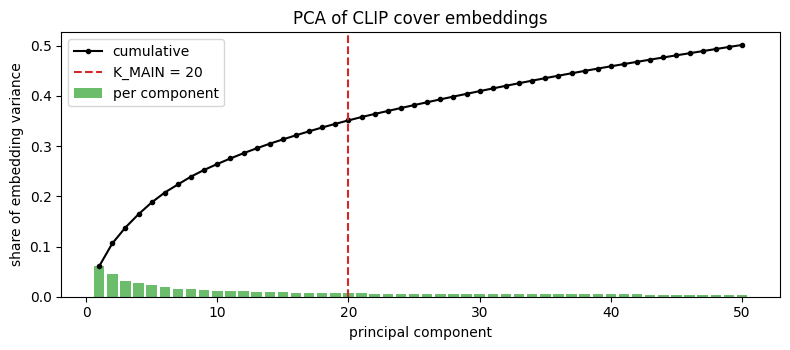

variance explained by the first 20 PCs: 35.1%


In [8]:
K_MAX = max(K_GRID)

def pca_scores(train_cover_rows, k_max=K_MAX):
    # Fit PCA on the given covers; return a function mapping song rows to PC scores.
    pca = PCA(n_components=min(k_max, len(train_cover_rows) - 1), random_state=SEED).fit(E_cover[train_cover_rows])
    return pca, (lambda song_rows: pca.transform(E[song_rows]))

pca_full, score_fn_full = pca_scores(np.arange(len(covers)))
U_raw = score_fn_full(np.arange(len(m)))
PC_NAMES = [f"z_pc{j + 1}" for j in range(U_raw.shape[1])]
U = (U_raw - U_raw.mean(0)) / U_raw.std(0)          # z-score each PC at the song level
m[PC_NAMES] = U

ev = pca_full.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(np.arange(1, len(ev) + 1), ev, color="tab:green", alpha=0.7, label="per component")
ax.plot(np.arange(1, len(ev) + 1), np.cumsum(ev), "k-o", ms=3, label="cumulative")
ax.axvline(K_MAIN, color="tab:red", ls="--", label=f"K_MAIN = {K_MAIN}")
ax.set(xlabel="principal component", ylabel="share of embedding variance", title="PCA of CLIP cover embeddings")
ax.legend(); plt.tight_layout(); plt.savefig(OUT_DIR / "pca_scree.png", dpi=200); plt.show()
print(f"variance explained by the first {K_MAIN} PCs: {ev[:K_MAIN].sum():.1%}")

## 6. Out-of-sample comparison: M0 vs M1

Both models are fitted on the same training folds and scored on the same held-out clusters. Inside each fold: z-score audio features and APS with training means and SDs, fit PCA on the training covers, z-score the PC scores with training values, fit one quantile regression per $\tau$, and predict the held-out songs.

**Pseudo-$R^2$** (Koenker-Machado), out of fold:

$$
R^1_{\text{oos}}(\tau) = 1 - \frac{\sum_i \rho_\tau\big(Y_i - \hat q^{(-g(i))}_\tau(S_i)\big)}{\sum_i \rho_\tau\big(Y_i - \hat q^{(-g(i))}_{\tau,0}\big)},
$$

where $\hat q_{\tau,0}$ is the unconditional $\tau$-quantile of the training fold. **Interval for the gain** $\Delta(\tau) = R^1_{\text{M1}} - R^1_{\text{M0}}$: resample clusters with replacement and recompute $\Delta$ from the stored out-of-fold losses. This captures test-set variability (not refitting variability), which is the usual practical compromise.

In [9]:
def check_loss(y, yhat, tau):
    e = y - yhat
    return np.maximum(tau * e, (tau - 1) * e)

yv = m[Y].to_numpy()
folds = list(GroupKFold(N_SPLITS).split(m, groups=groups))

def oof_predictions(k_list, use_audio_aps=True):
    # Out-of-fold predictions for every k in k_list (k = 0 is M0), plus the intercept-only baseline.
    preds = {k: {t: np.full(len(m), np.nan) for t in TAUS} for k in k_list}
    base  = {t: np.full(len(m), np.nan) for t in TAUS}
    for f, (tr, te) in enumerate(folds):
        Xa_tr, Xa_te = m.iloc[tr][XVARS].to_numpy(float), m.iloc[te][XVARS].to_numpy(float)
        mu, sd = Xa_tr.mean(0), Xa_tr.std(0, ddof=1)
        Xa_tr, Xa_te = (Xa_tr - mu) / sd, (Xa_te - mu) / sd
        if max(k_list) > 0:
            tr_covers = np.unique(song_cover_idx[tr])
            _, sfn = pca_scores(tr_covers)
            U_tr, U_te = sfn(tr), sfn(te)
            umu, usd = U_tr.mean(0), U_tr.std(0)
            U_tr, U_te = (U_tr - umu) / usd, (U_te - umu) / usd
        for t in TAUS:
            base[t][te] = np.quantile(yv[tr], t)
        for k in k_list:
            parts_tr = ([Xa_tr] if use_audio_aps else []) + ([U_tr[:, :k]] if k else [])
            parts_te = ([Xa_te] if use_audio_aps else []) + ([U_te[:, :k]] if k else [])
            X_tr = sm.add_constant(np.hstack(parts_tr), has_constant="add")
            X_te = sm.add_constant(np.hstack(parts_te), has_constant="add")
            for t in TAUS:
                b = sm.QuantReg(yv[tr], X_tr).fit(q=t, max_iter=5000).params
                preds[k][t][te] = X_te @ b
        print(f"  fold {f + 1}/{N_SPLITS} done")
    return preds, base

def pseudo_r2(pred, base, t, idx=slice(None)):
    return 1 - check_loss(yv[idx], pred[idx], t).sum() / check_loss(yv[idx], base[idx], t).sum()

print("Fitting the k-grid (this is the slow cell: one quantile regression per fold x k x tau)...")
oof, oof_base = oof_predictions(K_GRID)

Fitting the k-grid (this is the slow cell: one quantile regression per fold x k x tau)...
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done


C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


  fold 5/5 done


Out-of-fold pseudo-R2 by number of cover PCs (k = 0 is M0 on the same songs):


,k=0,k=2,k=5,k=10,k=20,k=30,k=50
tau=0.1,-0.0014,-0.0025,0.0002,0.0022,-0.0021,-0.0081,-0.0214
tau=0.25,0.0085,0.0094,0.0081,0.0067,0.0028,-0.0008,-0.0056
tau=0.5,0.0232,0.0257,0.0272,0.0280,0.0260,0.0245,0.0217
tau=0.75,0.0363,0.0401,0.0412,0.0421,0.0422,0.0438,0.0399
tau=0.9,0.0488,0.0541,0.0557,0.0574,0.0582,0.0586,0.0531


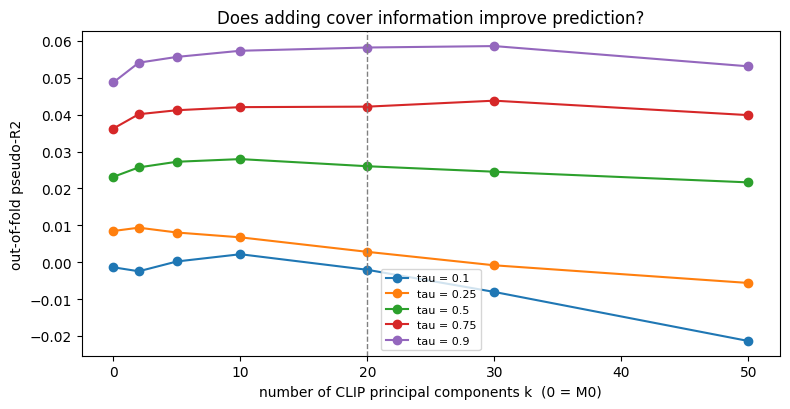

In [10]:
curve = pd.DataFrame({k: {t: pseudo_r2(oof[k][t], oof_base[t], t) for t in TAUS} for k in K_GRID})
curve.index = [f"tau={t}" for t in TAUS]; curve.columns = [f"k={k}" for k in K_GRID]
print("Out-of-fold pseudo-R2 by number of cover PCs (k = 0 is M0 on the same songs):")
display(curve.round(4))

fig, ax = plt.subplots(figsize=(8, 4.2))
for t in TAUS:
    ax.plot(K_GRID, [pseudo_r2(oof[k][t], oof_base[t], t) for k in K_GRID], "o-", label=f"tau = {t}")
ax.axvline(K_MAIN, color="grey", ls="--", lw=1)
ax.set(xlabel="number of CLIP principal components k  (0 = M0)", ylabel="out-of-fold pseudo-R2",
       title="Does adding cover information improve prediction?")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR / "k_sensitivity.png", dpi=200); plt.show()

In [11]:
# Gain of M1 (k = K_MAIN) over M0, with a cluster-bootstrap interval
def cluster_sums(v):
    return np.bincount(groups, weights=v, minlength=G)

W = rng.multinomial(G, np.full(G, 1 / G), size=N_BOOT)        # bootstrap weights per cluster
rows = []
for t in TAUS:
    L0 = cluster_sums(check_loss(yv, oof[0][t], t))
    L1 = cluster_sums(check_loss(yv, oof[K_MAIN][t], t))
    LB = cluster_sums(check_loss(yv, oof_base[t], t))
    r0, r1 = 1 - L0.sum() / LB.sum(), 1 - L1.sum() / LB.sum()
    d_boot = (W @ L0 - W @ L1) / (W @ LB)
    rows.append({"tau": t, "M0 pseudo-R2": r0, f"M1 (k={K_MAIN}) pseudo-R2": r1, "gain": r1 - r0,
                 "95% CI low": np.quantile(d_boot, 0.025), "95% CI high": np.quantile(d_boot, 0.975),
                 "share of draws with gain > 0": (d_boot > 0).mean()})
gain = pd.DataFrame(rows).set_index("tau")
print("Out-of-fold improvement from adding cover features (same songs, same folds):")
display(gain.round(4))

calib = pd.DataFrame({t: {"M0": np.mean(yv <= oof[0][t]), f"M1 (k={K_MAIN})": np.mean(yv <= oof[K_MAIN][t])}
                      for t in TAUS}).T
calib.index = [f"tau={t}" for t in TAUS]
print("Out-of-fold calibration: share of songs at or below the predicted quantile (should be close to tau):")
display(calib.round(3))

Out-of-fold improvement from adding cover features (same songs, same folds):


,M0 pseudo-R2,M1 (k=20) pseudo-R2,gain,95% CI low,95% CI high,share of draws with gain > 0
tau,,,,,,
0.10,-0.0014,-0.0021,-0.0007,-0.0106,0.0094,0.4335
0.25,0.0085,0.0028,-0.0057,-0.0118,0.0003,0.0300
0.50,0.0232,0.0260,0.0029,-0.0022,0.0077,0.8775
0.75,0.0363,0.0422,0.0059,0.0010,0.0108,0.9900
0.90,0.0488,0.0582,0.0095,0.0028,0.0159,0.9965


Out-of-fold calibration: share of songs at or below the predicted quantile (should be close to tau):


,M0,M1 (k=20)
tau=0.1,0.102,0.104
tau=0.25,0.251,0.250
tau=0.5,0.502,0.502
tau=0.75,0.749,0.750
tau=0.9,0.898,0.897


### How much does the cover know on its own?

Two extra comparisons help interpret the gain:

- **Cover only** (no audio, no APS): how much popularity the cover predicts by itself.
- **Leakage check:** how well the cover predicts the *artist's* APS. A cover often prints the artist's name, and CLIP can read text and may recognise famous artists. If covers predict APS well, the cover features partly measure fame, which is why APS stays in the model.

In [12]:
oof_cover_only, _ = oof_predictions([K_MAIN], use_audio_aps=False)
cover_only = pd.Series({f"tau={t}": pseudo_r2(oof_cover_only[K_MAIN][t], oof_base[t], t) for t in TAUS},
                       name=f"cover only (k={K_MAIN})")
display(pd.concat([curve[["k=0", f"k={K_MAIN}"]].rename(columns={"k=0": "M0: audio + APS",
                                                                f"k={K_MAIN}": "M1: audio + APS + cover"}),
                   cover_only], axis=1).round(4))

# Leakage check: predict APS from the cover PCs (artist-grouped CV, linear regression)
aps_v = m["APS"].to_numpy(float); aps_pred = np.full(len(m), np.nan)
for tr, te in folds:
    _, sfn = pca_scores(np.unique(song_cover_idx[tr]))
    aps_pred[te] = LinearRegression().fit(sfn(tr)[:, :K_MAIN], aps_v[tr]).predict(sfn(te)[:, :K_MAIN])
r2_aps = 1 - np.sum((aps_v - aps_pred) ** 2) / np.sum((aps_v - aps_v.mean()) ** 2)
print(f"Out-of-fold R2 of APS predicted from {K_MAIN} cover PCs: {r2_aps:.3f}  "
      "(near 0: covers carry little fame information; clearly above 0: they partly encode fame)")

  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done


,M0: audio + APS,M1: audio + APS + cover,cover only (k=20)
tau=0.1,-0.0014,-0.0021,-0.0048
tau=0.25,0.0085,0.0028,-0.0009
tau=0.5,0.0232,0.0260,0.0084
tau=0.75,0.0363,0.0422,0.0180
tau=0.9,0.0488,0.0582,0.0239


Out-of-fold R2 of APS predicted from 20 cover PCs: 0.130  (near 0: covers carry little fame information; clearly above 0: they partly encode fame)


## 7. Full-sample M1 fit and tests of the cover coefficients

The main model with $k$ = `K_MAIN` is fitted on all songs, using the full-sample PCA.

**Single coefficients.** Standard errors use the same cluster-robust sandwich estimator as M0 (Parente and Santos Silva, 2016), with the clusters from section 3. Because $k$ cover coefficients are tested at each $\tau$, their p-values are also Holm-adjusted across the $k$ PCs. In the same simulation these single tests had 5% false positives at $\tau=0.5$ and 7.5% at $\tau=0.9$; at $\tau=0.10$ they were less reliable (a pure-noise cover direction occasionally came out significant even after Holm). Treat an isolated star at $\tau=0.10$ with caution unless the joint test and the out-of-fold gain agree.

**Joint test of $H_0:\ \boldsymbol\theta(\tau)=\mathbf{0}$: why not the usual Wald test.** The textbook test is $W = \hat{\boldsymbol\theta}^\top \widehat V_\theta^{-1}\hat{\boldsymbol\theta} \sim \chi^2_k$ with the sandwich $\widehat V_\theta$. While building this notebook it was checked by simulation on the real songs: random "cover features" with no relation to popularity were added, and the test was run many times. With $k=5$ it behaved (about 5% false rejections). With $k=20$ it rejected **32% of the time at $\tau=0.5$ and 80% at $\tau=0.9$**. Twenty restrictions are too many for the sandwich estimate at this sample size: it is nearly singular in some directions, which blows up $W$. Single-coefficient tests were fine (5-7.5%).

**What is used instead.** A *cluster bootstrap* of the cover coefficients: resample whole clusters with replacement $B$ times, refit, and estimate $\widehat V^{\,*}_\theta = \operatorname{Cov}(\hat{\boldsymbol\theta}^{*}_1,\dots,\hat{\boldsymbol\theta}^{*}_B)$. Because $\widehat V^{\,*}_\theta$ is itself estimated from $B$ draws, the statistic is referred to Hotelling's $F$ distribution rather than $\chi^2$:

$$
T^2(\tau) = \hat{\boldsymbol\theta}(\tau)^\top \,\widehat V^{\,*}_\theta(\tau)^{-1}\, \hat{\boldsymbol\theta}(\tau), \qquad
F(\tau) = \frac{B-k}{k\,(B-1)}\,T^2(\tau) \;\sim\; F_{k,\,B-k}\ \text{under } H_0 .
$$

Each bootstrap draw refits all five quantiles on the same resample. With `N_BOOT_COV = 199` this is about 1,000 quantile regressions; expect several minutes. The out-of-fold gain in section 6 remains the main evidence, because it needs no distributional approximation at all.

In [13]:
def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def cluster_robust_cov(fits, X, y, groups, taus):
    # Artist-clustered sandwich covariance (Parente & Santos Silva 2016), as in M0.
    Xv = X.to_numpy(); n, k = Xv.shape
    g = pd.factorize(groups)[0]; Gc = g.max() + 1
    H_inv, scores = {}, {}
    for t in taus:
        e = y - Xv @ fits[t].params.to_numpy()
        iqr = np.subtract(*np.percentile(e, [75, 25]))
        h = hall_sheather(n, t) * min(e.std(), iqr / 1.34)
        dens = norm.pdf(e / h) / h
        H_inv[t] = np.linalg.inv((Xv * dens[:, None]).T @ Xv / n)
        s = np.zeros((Gc, k)); np.add.at(s, g, Xv * (t - (e < 0))[:, None]); scores[t] = s
    return {(a, b): H_inv[a] @ (scores[a].T @ scores[b] / n) @ H_inv[b] / n * Gc / (Gc - 1)
            for a in taus for b in taus}

# z-score audio + APS within the M1 sample (as M0 does within its sample)
for c in XVARS:
    m["z_" + c] = (m[c] - m[c].mean()) / m[c].std()

PCS = PC_NAMES[:K_MAIN]
models = {"M0": ZVARS, "M1": ZVARS + PCS}
fits, cov, se = {}, {}, {}
for name, cols in models.items():
    X = sm.add_constant(m[cols])
    fits[name] = {t: sm.QuantReg(yv, X).fit(q=t, max_iter=5000) for t in TAUS}
    cov[name]  = cluster_robust_cov(fits[name], X, yv, groups, TAUS)
    se[name]   = {t: pd.Series(np.sqrt(np.diag(cov[name][(t, t)])), index=X.columns) for t in TAUS}

X1 = sm.add_constant(m[models["M1"]])
vif = pd.Series([variance_inflation_factor(X1.values, i) for i in range(1, X1.shape[1])], index=models["M1"])
print(f"Largest VIF in M1: {vif.max():.2f} ({vif.idxmax()})  (PCs are uncorrelated with each other by construction)")

# ---------------- single cover coefficients: clustered t-tests, Holm-adjusted across the k PCs ----------------
def holm(p):
    p = np.asarray(p); mm = len(p); order = np.argsort(p)
    adj = np.minimum(np.maximum.accumulate((mm - np.arange(mm)) * p[order]), 1.0)
    out = np.empty(mm); out[order] = adj; return out

pc_p = {t: pd.Series(2 * norm.sf(np.abs(fits["M1"][t].params[PCS] / se["M1"][t][PCS])), index=PCS) for t in TAUS}
pc_holm = {t: pd.Series(holm(pc_p[t].to_numpy()), index=PCS) for t in TAUS}

# ---------------- joint test: cluster-bootstrap covariance + Hotelling F ----------------
members = [np.flatnonzero(groups == c) for c in range(G)]
th_draws = {t: [] for t in TAUS}
print(f"Cluster bootstrap for the joint test: {N_BOOT_COV} draws x {len(TAUS)} quantiles ...")
for b in range(N_BOOT_COV):
    idx = np.concatenate([members[c] for c in rng.integers(0, G, G)])
    Xb, yb = X1.iloc[idx], yv[idx]
    for t in TAUS:
        th_draws[t].append(sm.QuantReg(yb, Xb).fit(q=t, max_iter=5000).params[PCS].to_numpy())
    if (b + 1) % 25 == 0:
        print(f"  {b + 1}/{N_BOOT_COV}")

wald = []
for t in TAUS:
    th = fits["M1"][t].params[PCS].to_numpy()
    Vb = np.cov(np.array(th_draws[t]), rowvar=False)
    T2 = float(th @ np.linalg.solve(Vb, th))
    Fst = T2 * (N_BOOT_COV - K_MAIN) / (K_MAIN * (N_BOOT_COV - 1))
    wald.append({"tau": t, "Hotelling T2": T2, f"F (df={K_MAIN},{N_BOOT_COV - K_MAIN})": Fst,
                 "p-value (joint)": fdist.sf(Fst, K_MAIN, N_BOOT_COV - K_MAIN),
                 "PCs significant after Holm (5%)": int((pc_holm[t] < 0.05).sum()),
                 "in-sample pseudo-R2 M0": fits["M0"][t].prsquared,
                 "in-sample pseudo-R2 M1": fits["M1"][t].prsquared})
wald = pd.DataFrame(wald).set_index("tau")
print("H0: all cover coefficients are zero (cluster-bootstrap covariance, Hotelling F):")
display(wald.round(4))

Largest VIF in M1: 3.57 (z_energy)  (PCs are uncorrelated with each other by construction)
Cluster bootstrap for the joint test: 199 draws x 5 quantiles ...


C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +
C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


  25/199


C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +
C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


  50/199


C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +
C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


... (4 outputs left out)

  125/199
  150/199
  175/199


C:\Users\kiwib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


H0: all cover coefficients are zero (cluster-bootstrap covariance, Hotelling F):


,Hotelling T2,"F (df=20,179)",p-value (joint),PCs significant after Holm (5%),in-sample pseudo-R2 M0,in-sample pseudo-R2 M1
tau,,,,,,
0.10,50.9195,2.3017,0.0021,1,0.0100,0.0260
0.25,31.5939,1.4281,0.1141,0,0.0133,0.0200
0.50,77.0515,3.4829,0.0000,2,0.0262,0.0359
0.75,81.1841,3.6697,0.0000,2,0.0393,0.0509
0.90,106.8081,4.8279,0.0000,4,0.0544,0.0693


In [14]:
# Audio and APS coefficients: M0 vs M1 on the same songs (does the cover absorb any effect?)
rows = {}
for t in TAUS:
    for name in ["M0", "M1"]:
        b, s = fits[name][t].params, se[name][t]
        p = pd.Series(2 * norm.sf(np.abs(b / s)), index=b.index)
        rows[(f"tau={t}", name)] = [f"{b[c]:.3f}{stars(p[c])}" for c in ["const"] + ZVARS]
compare = pd.DataFrame(rows, index=[LABEL[c] for c in ["const"] + ZVARS])
print("Coefficients (points per +1 SD), artist-clustered stars: *** p<0.01, ** p<0.05, * p<0.10")
display(compare)

aps_shift = pd.DataFrame({t: {"gamma M0": fits["M0"][t].params["z_APS"], "gamma M1": fits["M1"][t].params["z_APS"]}
                          for t in TAUS}).T
aps_shift["change"] = aps_shift["gamma M1"] - aps_shift["gamma M0"]
aps_shift["% change"] = 100 * aps_shift["change"] / aps_shift["gamma M0"]
print("Artist-score effect with and without cover features:")
display(aps_shift.round(3))

Coefficients (points per +1 SD), artist-clustered stars: *** p<0.01, ** p<0.05, * p<0.10


tau=0.1              tau=0.25               tau=0.5              tau=0.75               tau=0.9           
                           M0         M1         M0         M1         M0         M1         M0         M1         M0         M1
Intercept           21.992***  22.726***  45.614***  45.271***  60.559***  60.642***  69.644***  69.439***  76.129***  75.848***
duration                0.519      0.405     0.922*      0.695   0.823***    0.915**    0.575**   0.730***      0.257      0.391
acousticness            0.244      0.417     -0.871     -0.878  -1.466***  -1.182***  -1.261***  -1.010***    -0.529*     -0.537
danceability         2.725***     2.085*     0.937*      1.095      0.259      0.450   0.831***    0.691**   1.312***   1.174***
energy                 -1.955     -1.618    -1.518*     -1.483  -2.411***  -2.621***  -1.683***  -1.609***  -1.487***   -1.028**
instrumentalness    -1.194***    -1.013*   -1.462**  -1.221***   -0.943**  -1.124***  -0.895***  -1.090***  -0.762***  -0.896***
liveness               -0.908     -0.874  -1.391***   -1.328**  -1.206***  -0.992***   -0.591**     -0.364    -0.327*  -0.526***
loudness                0.567      0.458    1.967**     1.422*   2.586***   1.994***   1.775***   1.501***   1.941***   1.484***
speechiness             0.021     -0.687     -0.598     -0.479     -0.370     -0.142   -0.568**   -0.574**     -0.268     -0.257
tempo                   0.537     -0.089      0.558      0.580     -0.381     -0.208     -0.272     -0.326     -0.111     -0.030
valence                 0.438      0.509     -0.720     -0.197     -0.208      0.229   -0.610**      0.010  -1.004***    -0.608*
APS (artist score)      0.851      1.311   2.233***   1.990***   3.006***   2.954***   2.864***   2.683***   2.818***   2.860***

Artist-score effect with and without cover features:


,gamma M0,gamma M1,change,% change
0.10,0.851,1.311,0.460,53.969
0.25,2.233,1.990,-0.242,-10.848
0.50,3.006,2.954,-0.052,-1.739
0.75,2.864,2.683,-0.181,-6.318
0.90,2.818,2.860,0.042,1.492


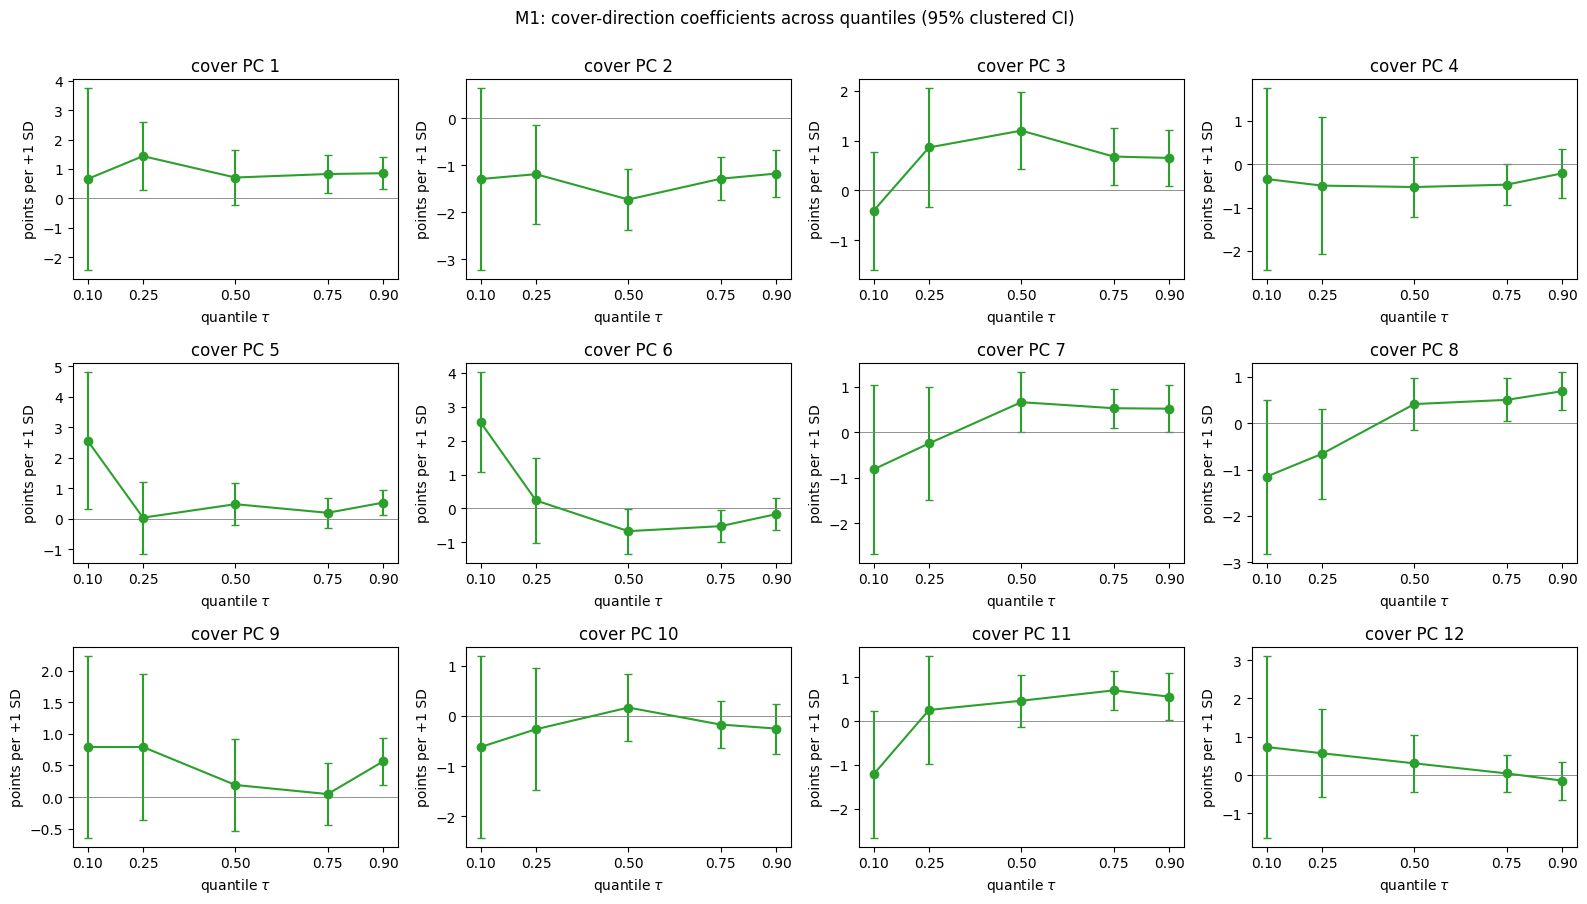

Cover coefficients (points per +1 SD); stars use Holm-adjusted clustered p-values across the k PCs:


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
z_pc1,0.656,1.436,0.707,0.826,0.853**
z_pc2,-1.293,-1.190,-1.729***,-1.287***,-1.177***
z_pc3,-0.411,0.862,1.200**,0.679,0.651
z_pc4,-0.341,-0.493,-0.525,-0.471,-0.210
z_pc5,2.559,0.029,0.471,0.189,0.522
z_pc6,2.545**,0.236,-0.671,-0.523,-0.169
z_pc7,-0.815,-0.245,0.659,0.527,0.516
z_pc8,-1.152,-0.662,0.411,0.502,0.688**
z_pc9,0.791,0.791,0.190,0.046,0.563**
z_pc10,-0.620,-0.265,0.167,-0.172,-0.252


In [15]:
# Cover coefficients theta(tau) with 95% clustered intervals, first 12 PCs
show = PCS[:12]
fig, axes = plt.subplots(3, 4, figsize=(16, 9)); axes = axes.ravel()
for ax, c in zip(axes, show):
    est = [fits["M1"][t].params[c] for t in TAUS]; s = [se["M1"][t][c] for t in TAUS]
    ax.errorbar(TAUS, est, yerr=1.96 * np.array(s), fmt="o-", color="tab:green", capsize=3)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set(title=c.replace("z_pc", "cover PC "), xlabel=r"quantile $\tau$", ylabel="points per +1 SD"); ax.set_xticks(TAUS)
for ax in axes[len(show):]: ax.axis("off")
fig.suptitle("M1: cover-direction coefficients across quantiles (95% clustered CI)", y=1.0)
plt.tight_layout(); plt.savefig(OUT_DIR / "cover_coefficients_by_quantile.png", dpi=200); plt.show()

theta_tab = pd.DataFrame({f"tau={t}": [f"{fits['M1'][t].params[c]:.3f}{stars(pc_holm[t][c])}" for c in PCS]
                          for t in TAUS}, index=PCS)
print("Cover coefficients (points per +1 SD); stars use Holm-adjusted clustered p-values across the k PCs:")
display(theta_tab)

## 8. What do the cover directions mean?

A principal component is just a direction in CLIP space, so it needs interpreting. Two tools:

1. **Extreme covers:** the covers with the highest and lowest scores on a PC.
2. **Text probes:** CLIP can embed text into the same space. For each prompt $p$, the concept score of cover $i$ is $c_i(p) = \cos\big(z_i, t(p)\big)$. Correlating PC scores with concept scores across covers gives each PC a plain-language description.

Edit `PROMPTS` freely: they are descriptions, not data, and changing them does not change any model result.

,high end of PC | low end of PC
PC1,+ a cartoon or anime illustration; a hip-hop album cover | - a photo of a band performing live; a vintage photo from the 1970s
PC2,+ a country music album cover; a hip-hop album cover | - a minimalist design with lots of empty space; an abstract geometric design
PC3,+ a country music album cover; a sexy fashion photo | - a hip-hop album cover; a heavy metal album cover
PC4,+ an abstract geometric design; a cover with only text and typography | - a sexy fashion photo; a close-up portrait photo of a person's face
PC5,"+ a cartoon or anime illustration; a cover with only text and typography | - a dark, moody album cover; a hand-drawn painting"
PC6,"+ a vintage photo from the 1970s; a cartoon or anime illustration | - a dark, moody album cover; a heavy metal album cover"
PC7,"+ a bright, colourful album cover; a sexy fashion photo | - a black and white photo; a country music album cover"
PC8,"+ a bright, colourful album cover; a vintage photo from the 1970s | - a close-up portrait photo of a person's face; an abstract geometric design"
PC9,"+ a heavy metal album cover; a bright, colourful album cover | - a landscape or nature photo; a black and white photo"
PC10,"+ a sexy fashion photo; a dark, moody album cover | - a bright, colourful album cover; an abstract geometric design"


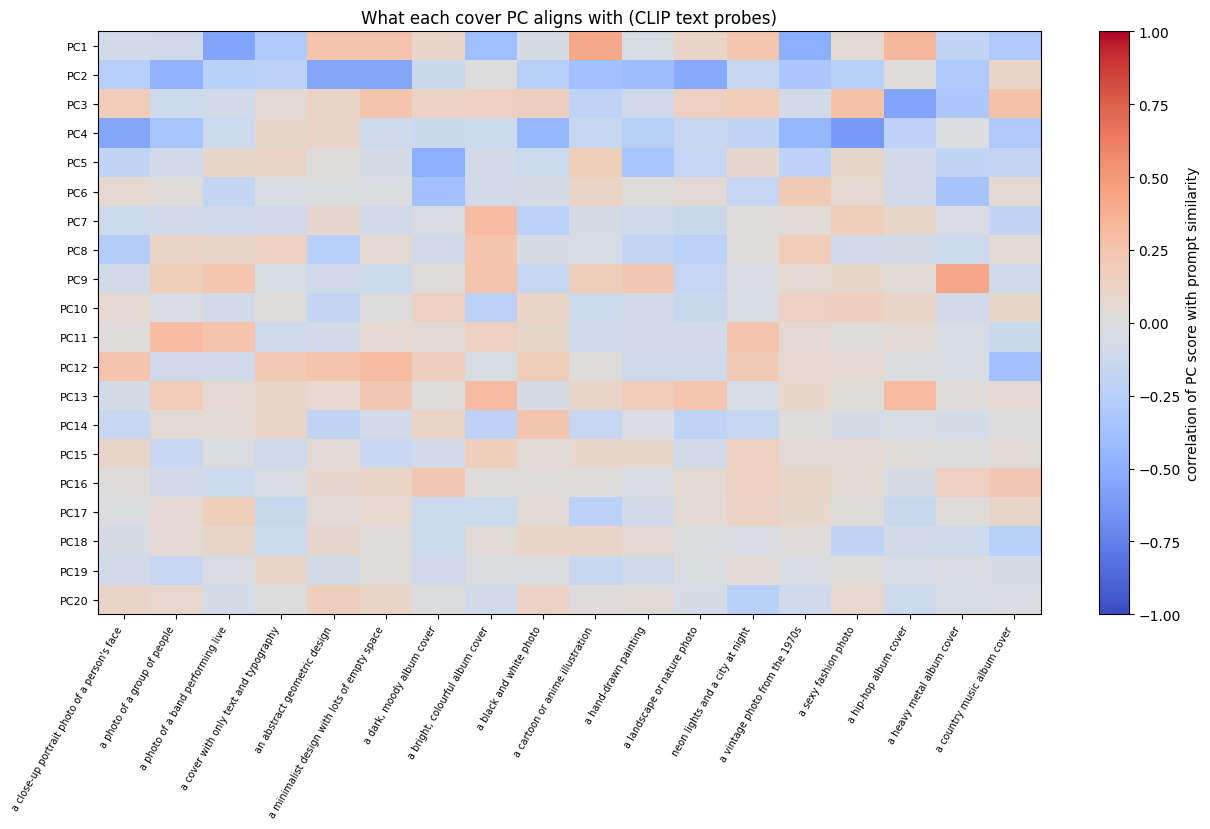

In [16]:
PROMPTS = [
    "a close-up portrait photo of a person's face", "a photo of a group of people", "a photo of a band performing live",
    "a cover with only text and typography", "an abstract geometric design", "a minimalist design with lots of empty space",
    "a dark, moody album cover", "a bright, colourful album cover", "a black and white photo",
    "a cartoon or anime illustration", "a hand-drawn painting", "a landscape or nature photo",
    "neon lights and a city at night", "a vintage photo from the 1970s", "a sexy fashion photo",
    "a hip-hop album cover", "a heavy metal album cover", "a country music album cover",
]
T = encode_texts(PROMPTS)
T = T / np.linalg.norm(T, axis=1, keepdims=True)
concept = E_cover @ T.T                                   # cover x prompt cosine similarities
pc_cover = pca_full.transform(E_cover)[:, :K_MAIN]        # PC scores at the cover level

corr = pd.DataFrame([[np.corrcoef(pc_cover[:, j], concept[:, p])[0, 1] for p in range(len(PROMPTS))]
                     for j in range(K_MAIN)], index=[f"PC{j + 1}" for j in range(K_MAIN)], columns=PROMPTS)

def describe(j, n=2):
    r = corr.iloc[j].sort_values()
    return ("+ " + "; ".join(r.index[-n:][::-1]) + "   |   - " + "; ".join(r.index[:n]))

pc_desc = pd.DataFrame({"high end of PC  |  low end of PC": [describe(j) for j in range(K_MAIN)]},
                       index=[f"PC{j + 1}" for j in range(K_MAIN)])
pd.set_option("display.max_colwidth", 200)
display(pc_desc)

fig, ax = plt.subplots(figsize=(13, 0.32 * K_MAIN + 2))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(PROMPTS))); ax.set_xticklabels(PROMPTS, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(K_MAIN)); ax.set_yticklabels(corr.index, fontsize=8)
plt.colorbar(im, label="correlation of PC score with prompt similarity")
ax.set_title("What each cover PC aligns with (CLIP text probes)")
plt.tight_layout(); plt.savefig(OUT_DIR / "pc_text_probes.png", dpi=200); plt.show()

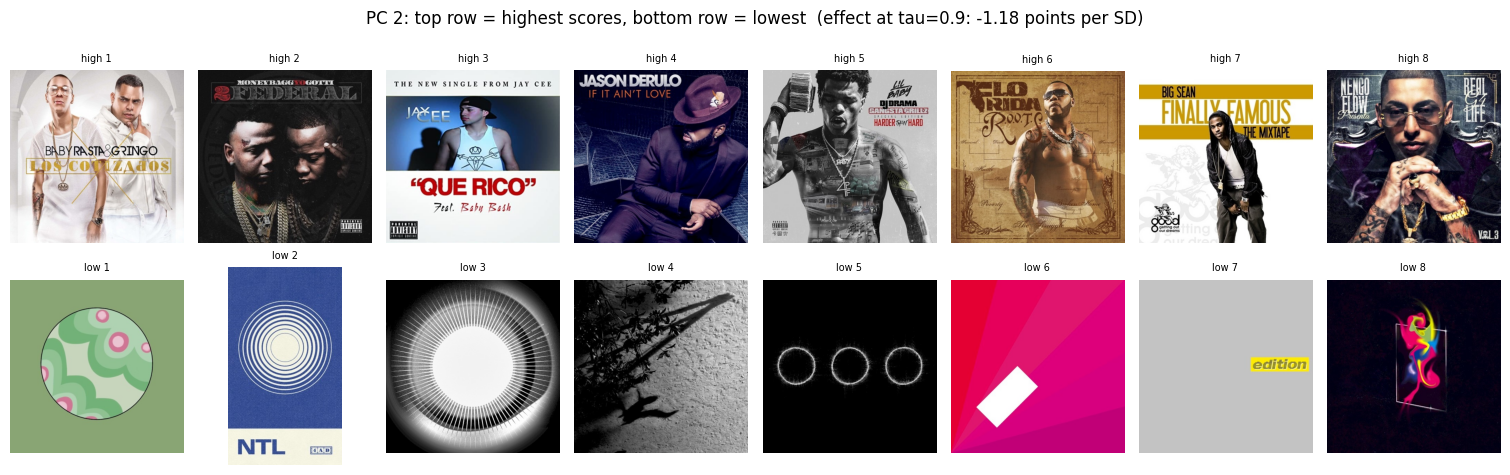

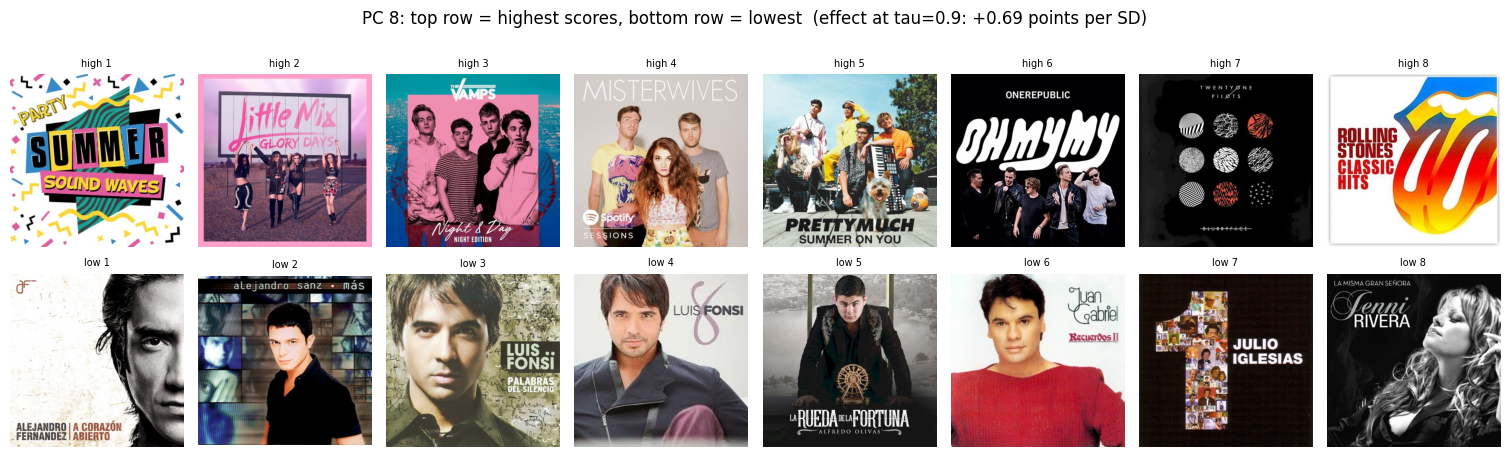

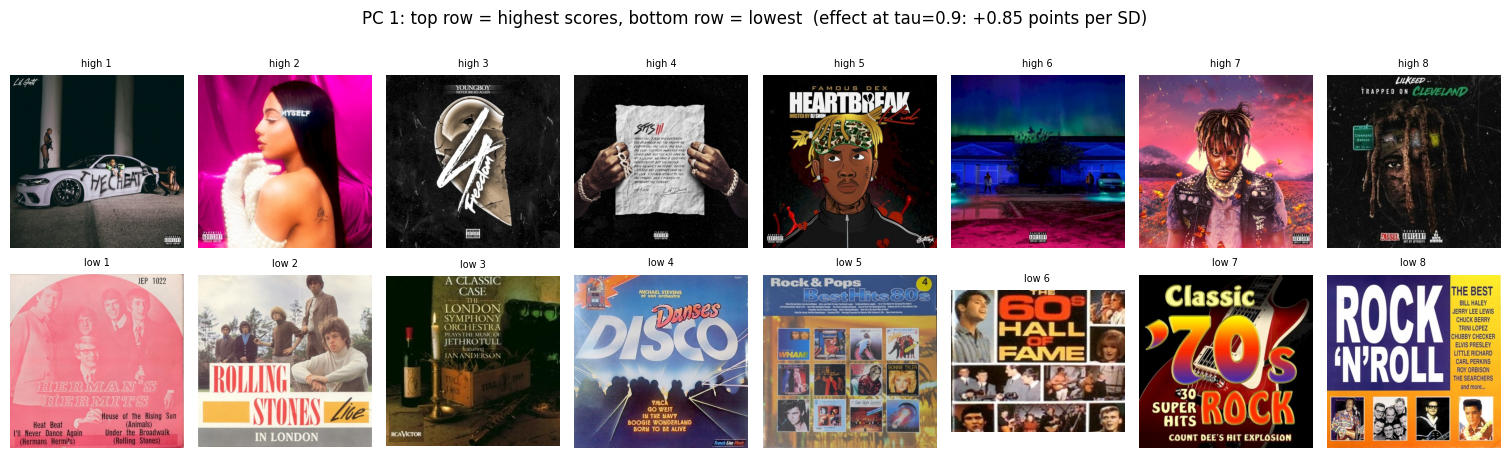

In [17]:
# Extreme covers for the PCs with the largest effect at the 90th percentile
top_pcs = (pd.Series({c: abs(fits["M1"][0.90].params[c] / se["M1"][0.90][c]) for c in PCS})
           .sort_values(ascending=False).index[:3])
for c in top_pcs:
    j = PC_NAMES.index(c)
    order = np.argsort(pc_cover[:, j])
    rows = list(order[::-1][:8]) + list(order[:8])
    titles = [f"high {i + 1}" for i in range(8)] + [f"low {i + 1}" for i in range(8)]
    b90 = fits["M1"][0.90].params[c]
    show_covers(rows, titles, suptitle=f"{c.replace('z_pc', 'PC ')}: top row = highest scores, bottom row = lowest  "
                                       f"(effect at tau=0.9: {b90:+.2f} points per SD)",
                fname=f"extremes_{c}.png")

## 9. Save results

In [18]:
curve.to_csv(OUT_DIR / "oof_pseudo_r2_by_k.csv")
gain.to_csv(OUT_DIR / "m1_vs_m0_gain.csv")
calib.to_csv(OUT_DIR / "oof_calibration.csv")
wald.to_csv(OUT_DIR / "wald_test_cover_coefficients.csv")
compare.to_csv(OUT_DIR / "coefficients_m0_vs_m1.csv")
aps_shift.to_csv(OUT_DIR / "aps_effect_m0_vs_m1.csv")
theta_tab.to_csv(OUT_DIR / "cover_coefficients.csv")
pc_desc.to_csv(OUT_DIR / "pc_descriptions.csv")
corr.to_csv(OUT_DIR / "pc_text_probe_correlations.csv")
pd.DataFrame({"rg_id": covers["rg_id"], **{f"pc{j + 1}": pc_cover[:, j] for j in range(K_MAIN)}}) \
  .to_csv(OUT_DIR / "cover_pc_scores.csv", index=False)
print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\kiwib\Desktop\Latex\Spotify Project\m1_outputs


## How to read the results

- **The cover adds information** if the joint test rejects $\boldsymbol\theta(\tau)=\mathbf{0}$ *and* the out-of-fold gain is positive with an interval above zero. A significant joint test with no out-of-sample gain means the cover patterns found in this sample do not carry over to new artists.
- **Differences across $\tau$** (e.g. a gain only at 0.9) would mean covers matter mostly for hits, or mostly for flops.
- **A falling APS coefficient** from M0 to M1, together with a high leakage $R^2$, means the cover partly measures fame. The cover effect *net of* fame is what $\boldsymbol\theta$ measures, because APS stays in the model.
- **A null result is a result:** "once you know the sound and the artist, the cover adds nothing" is worth reporting.
- **Do not use the textbook $\chi^2$ Wald test with many cover PCs:** section 7 shows it produces false positives at this sample size.
- **Linearity (assumption 1)** is not tested here beyond the $k$-curve. If M1 shows little gain, the nonlinear M2 models check whether a linear model was simply too restrictive.
- **Caveats** from the slides still apply: one cover per album, release era, selection into the cover sample, and no causal interpretation.